# Remaining resource features

Stage 05 combines Stage 03 prior-date smoothed quality with Stage 04 pre-event availability. Contract: `resource_sums_v2`. It produces resource sums and the five-group feature contract used by Stage 06. No model training, split, probability evaluation or NWC is performed here.

The resource export is verified against its source manifests before use. See `docs/current_workflow.md` for the complete 01-10 workflow and execution controls.


In [9]:
from pathlib import Path
import importlib
import json
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / 'config/remaining_resources.json').is_file()
             and (p / 'src/remaining_resource_features.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook inside the project directory.')
sys.path.insert(0, str(ROOT / 'src'))
import remaining_resource_features as stage
import remaining_resource_visualisation as viz
from audit_visualisation import table
importlib.reload(stage)
importlib.reload(viz)
RUN_STAGE = False
SAVE_FIGURES = True
OUTPUT = ROOT / stage.REPORT_DIR
DATA = ROOT / stage.DATA_DIR
print('Project:', ROOT)
print('Python:', sys.executable)


Project: D:\T20_Project\T20_Project_3.0
Python: d:\T20_Project\T20_Project_3.0\.venv\Scripts\python.exe


## 1. Build or verify

The common sample consists of Stage 04 ready whole matches. Reviews remain separately recorded, not silently removed from upstream histories. Initial XIs and current actors use stable IDs. Failed joins are errors, not cold starts. Stage 04 already distinguishes the current pair, never-entered waiting players, and previously entered players.


In [10]:
if RUN_STAGE:
    stage.run(ROOT)
summary = stage.verified_output(ROOT)
contract = json.loads((OUTPUT / 'feature_contract.json').read_text(encoding='utf-8'))
print('Verified resource export:', summary['resource_id'])
print('Contract version:', contract['contract_version'])
print('Upstream availability export:', summary['upstream_availability_id'])
display(table(pd.DataFrame([{'Check': k, 'Passed': v} for k, v in summary['checks'].items()]), 'Export checks'))


Verified resource export: fcc1d52d5696f4ed5829a984f7ad65cc634a973f4bc2fe26899891bfa2fc2a2d
Contract version: resource_sums_v2
Upstream availability export: e87e817800131e0c54c1e37c3baae23579ad457f1ced6d5daaace6f9292275f3


Check,Passed
same_whole_match_cohort_for_all_arms,True
stage03_source_files_unchanged,True
direct_quality_and_evidence_removed_from_model_input,True
stage04_source_order_and_actor_ids_match,True
finite_resources,True
per_player_sums_reconciled,True
no_usage_allocation_or_centering,True


## 2. One cohort for all comparisons

All five arms use the same events and complete-date splits. The four learned groups use identical candidate algorithm/parameter grids and validation selection rules. R0 estimates a constant probability from training-event outcome prevalence; it does not search algorithm/parameter grids. Resource eligibility is determined at whole-match level using Stage 04 availability checks.


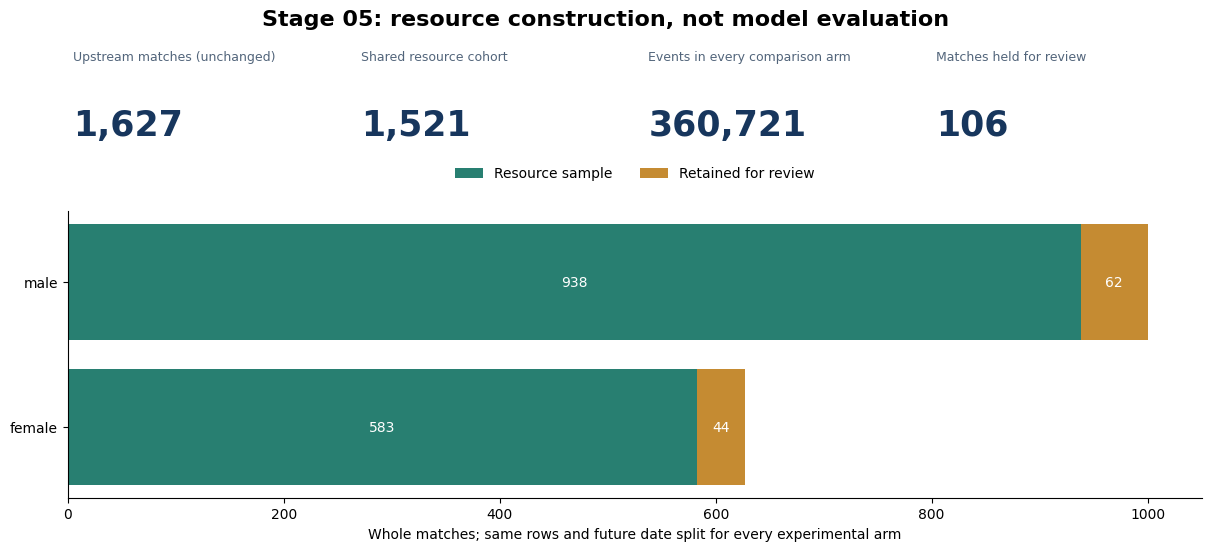

gender,included_in_resource_sample,matches,events
female,False,44,10413
female,True,583,137309
male,False,62,14652
male,True,938,223412


match_id,gender,match_date,source_events,replayed_events,status,ready_for_resource_features,reasons,included_in_resource_sample
222678,male,2005-10-21,233,233,review_required,False,match_replacement_restrictions_unverified,False
251488,male,2006-12-26,230,230,review_required,False,role_replacement_restrictions_unverified,False
255954,male,2006-12-01,248,248,review_required,False,role_replacement_restrictions_unverified,False
287874,male,2007-09-20,185,185,review_required,False,role_replacement_restrictions_unverified,False
287875,male,2007-09-20,246,246,review_required,False,role_replacement_restrictions_unverified,False
343764,male,2008-04-20,228,228,review_required,False,role_replacement_restrictions_unverified,False
426723,male,2009-11-12,235,235,review_required,False,role_replacement_restrictions_unverified | untimed_absent_hurt,False
518954,male,2012-02-01,248,248,review_required,False,bowling_return_penalty_time_unverified | role_replacement_restrictions_unverified,False
533301,female,2012-09-27,246,246,review_required,False,role_replacement_restrictions_unverified,False
560921,male,2012-06-30,251,251,review_required,False,retirement_return_conditions_unverified | role_replacement_restrictions_unverified | untimed_absent_hurt,False


Resource matches / events: 1521 / 360721


In [11]:
coverage = pd.read_csv(OUTPUT / 'coverage.csv')
reviews = pd.read_csv(OUTPUT / 'review_matches.csv')
figures = viz.build_figures(ROOT, summary)
display(figures['resource_coverage.png'])
display(table(coverage, 'Common resource cohort'))
display(table(reviews, 'Retained matches needing resource review', collapsed=True))
print('Resource matches / events:', summary['matches'], '/', summary['events'])


## 3. Remaining batting resources

For each batting metric, sum Stage 03's smoothed values across currently available players who have **never entered this innings**. Exclude both current batters, dismissed players, previously entered/returned players, and unavailable or replaced players. A player entering as non-striker leaves this pool immediately, before facing a ball.

The four metrics retain their original units. They are not centered against a reference and are not combined into a composite score. Higher batting dot rate is not better quality. Empty pools give zero; zero on a single metric does not prove there are no players.


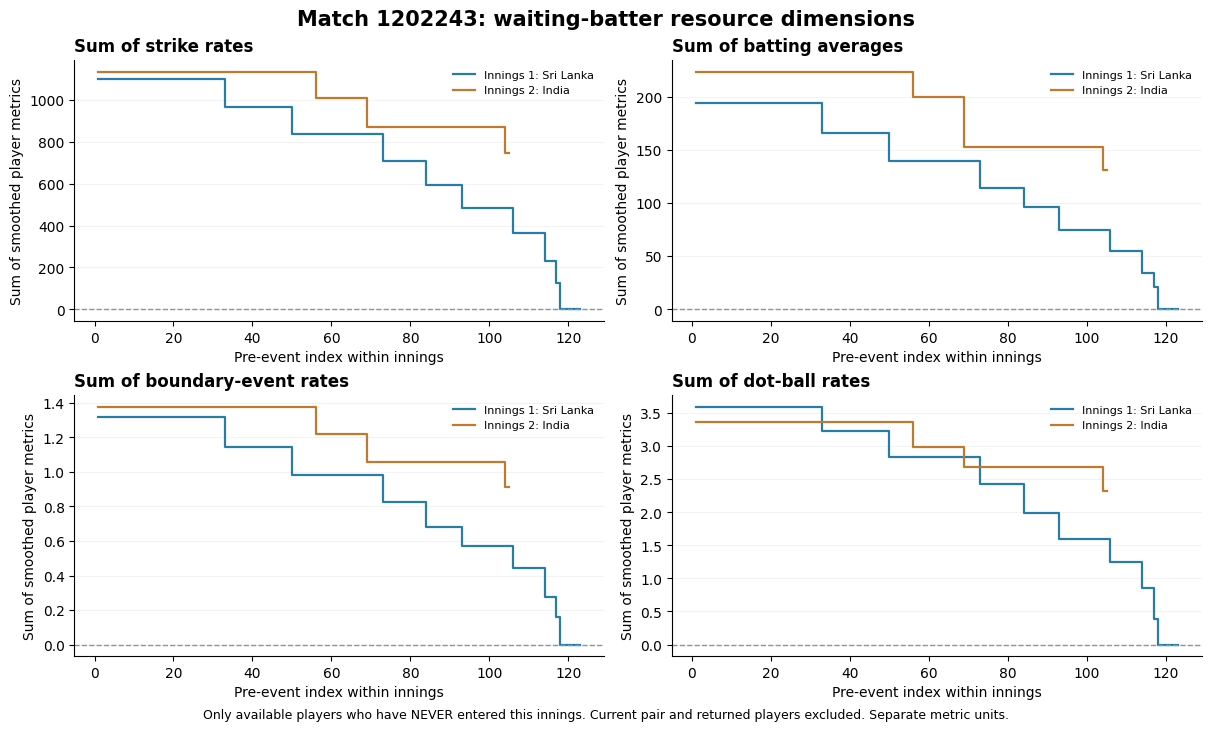

Calendar-selected match: 1202243


source_row,match_id,match_innings,event_sequence,audit_waiting_batter_count,waiting_resource_batting_strike_rate,waiting_resource_batting_average,waiting_resource_batting_boundary_rate,waiting_resource_batting_dot_rate
144961,1202243,1,1,9,1100.500634,194.564086,1.318855,3.593675
144962,1202243,1,2,9,1100.500634,194.564086,1.318855,3.593675
144963,1202243,1,3,9,1100.500634,194.564086,1.318855,3.593675
144964,1202243,1,4,9,1100.500634,194.564086,1.318855,3.593675
144965,1202243,1,5,9,1100.500634,194.564086,1.318855,3.593675
144966,1202243,1,6,9,1100.500634,194.564086,1.318855,3.593675
144967,1202243,1,7,9,1100.500634,194.564086,1.318855,3.593675
144968,1202243,1,8,9,1100.500634,194.564086,1.318855,3.593675
144969,1202243,1,9,9,1100.500634,194.564086,1.318855,3.593675
144970,1202243,1,10,9,1100.500634,194.564086,1.318855,3.593675


In [12]:
display(figures['waiting_batting_resources.png'])
example = viz.load_example(ROOT)
print('Calendar-selected match:', int(example.match_id.iloc[0]))
display(table(example[stage.KEYS + ['audit_waiting_batter_count'] + stage.BAT_FEATURES].head(12), 'Never-entered batting resource sums'))


## 4. Remaining bowling resources

For each bowling metric, compute `sum(remaining nominal balls / 6 * smoothed bowling metric)`. Include the current bowler's remaining capacity and its quality weighting. Use Stage 04's over-slot accounting, including documented special overs; do not replace it with a blanket 24-minus-balls formula.

There is no workload prediction, historical-use allocation, current-over reservation, weighted average, or innings-budget normalization. Individual capacities can sum to more than the innings budget: these are remaining upper bounds, not a forecast that every bowler will use them. Preserve each metric separately; higher economy is not better quality.


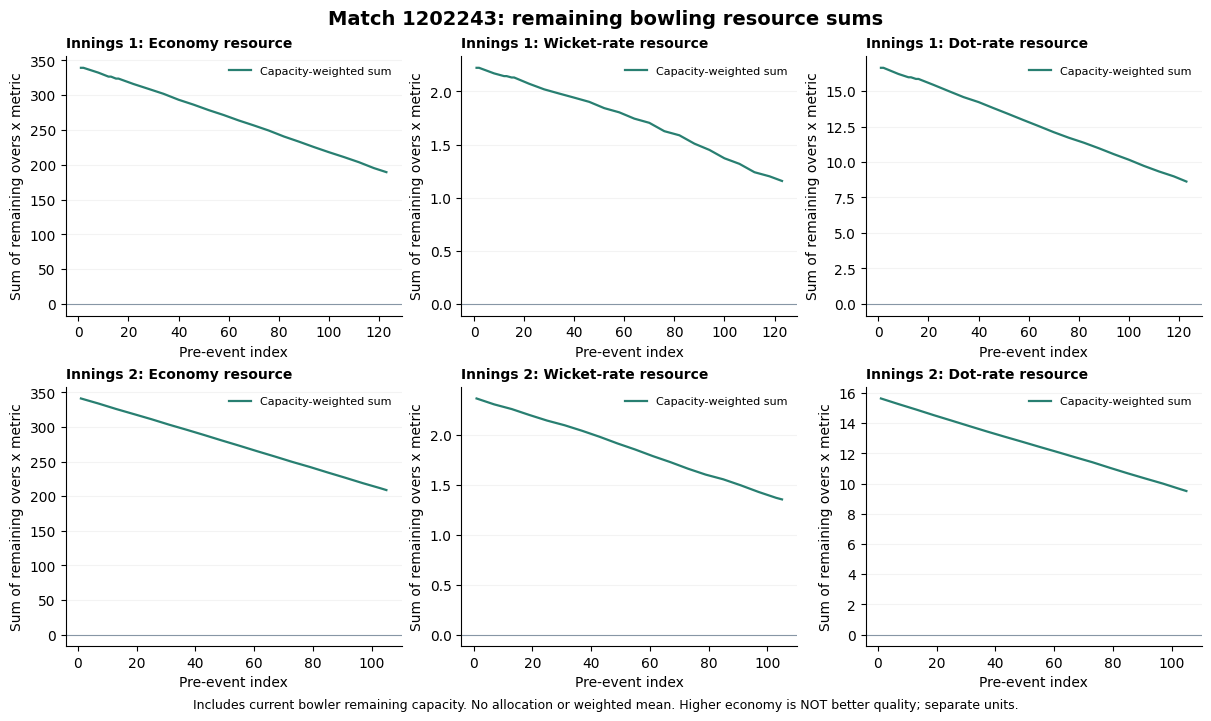

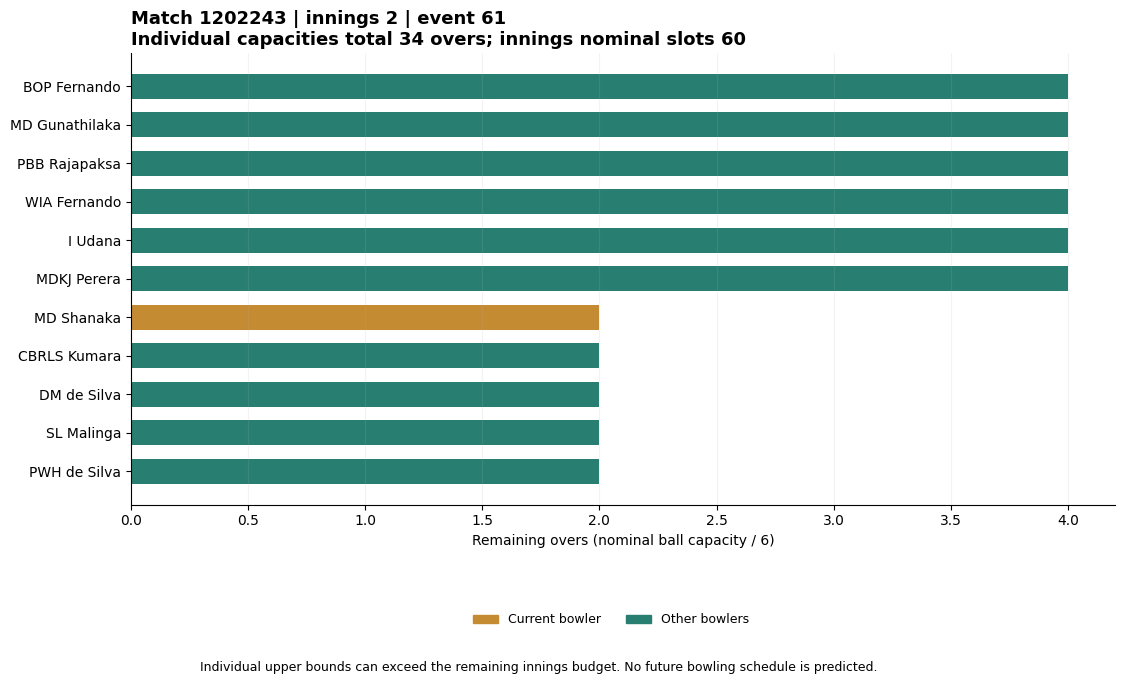

Check,Value
max_batting_sum_error,0.0
max_bowling_sum_error,0.0
zero_nominal_budget_events,0.0


In [13]:
display(figures['remaining_bowling_resources.png'])
display(figures['bowling_capacity_example.png'])
display(table(pd.DataFrame([{'Check': k, 'Value': v} for k, v in summary['reconciliation'].items()]), 'Per-player sum reconciliation'))


## 5. Feature groups for the main experiment

Five groups: constant baseline; match state/background; add batting resources; add bowling resources; add both. The group labels are R0/R1/RB/RW/RBW. Current striker, non-striker and bowler direct quality and associated evidence are excluded from all allowlists and from the model-input export.

Capacity and history-coverage diagnostics remain available for auditing, not extra model inputs in only one arm. The four nonconstant arms share the same state/background block; all five arms use the same first-batting-team target. Stage 07 constructs its symmetric progress interactions separately from these resource sums.


In [14]:
arm_rows = []
for code, name in contract['arm_codes'].items():
    arm_rows.append({'Code': code, 'Arm': name, 'Candidate columns': len(contract['main_arms'][name])})
display(table(pd.DataFrame(arm_rows), 'Prepared comparisons; no training'))
display(table(pd.DataFrame([
    {'Block': 'Batting resources', 'Fields': ', '.join(stage.BAT_FEATURES)},
    {'Block': 'Bowling resources', 'Fields': ', '.join(stage.BOWL_FEATURES)},
    {'Block': 'Capacity diagnostics ONLY', 'Fields': ', '.join(stage.CAPACITY_DIAGNOSTICS)}
]), 'Resource blocks'))


Code,Arm,Candidate columns
R0,constant,0
R1,state,16
RB,batting_resources,20
RW,bowling_resources,19
RBW,both_resources,23


Block,Fields
Batting resources,"waiting_resource_batting_strike_rate, waiting_resource_batting_average, waiting_resource_batting_boundary_rate, waiting_resource_batting_dot_rate"
Bowling resources,"bowling_resource_bowling_economy, bowling_resource_bowling_wicket_rate, bowling_resource_bowling_dot_rate"
Capacity diagnostics ONLY,"audit_current_bowler_capacity, audit_bowlers_with_capacity, audit_total_remaining_overs"


## 6. Audit and limitations

Serialized per-player contributions must reproduce every resource sum. Inputs must be finite; nominal capacity is bounded by the Stage 04 policy; unavailable/exhausted bowlers contribute zero. All event keys and current actors must match upstream.

Player quality is strictly prior-date. Future appearances, actual later bowling assignments, outcomes, IDs and review flags are not predictors. Removing standalone current-player quality does not make the model independent of player history: the current bowler still contributes through its remaining resource. No prediction improvement or causal NWC is established here.


In [15]:
checks = pd.read_csv(OUTPUT / 'resource_checks.csv')
feature_summary = pd.read_csv(OUTPUT / 'resource_feature_summary.csv')
display(table(checks.head(12), 'Per-match sum checks'))
display(table(feature_summary[['feature', 'mean', 'std', 'min', 'max']], 'Resource distributions', collapsed=True))
print('Constant resource fields:', feature_summary.loc[feature_summary['min'].eq(feature_summary['max']), 'feature'].tolist())


match_id,events,max_batting_sum_error,max_bowling_sum_error,zero_nominal_budget_events
211028,215,0.0,0.0,0
211048,245,0.0,0.0,0
225263,238,0.0,0.0,0
225271,253,0.0,0.0,0
226374,239,0.0,0.0,0
238195,249,0.0,0.0,0
249227,249,0.0,0.0,0
258463,249,0.0,0.0,0
258464,249,0.0,0.0,0
287853,252,0.0,0.0,0


feature,mean,std,min,max
waiting_resource_batting_strike_rate,724.164351,267.852171,0.000000,1263.055611
waiting_resource_batting_average,125.575338,48.680558,0.000000,251.250387
waiting_resource_batting_boundary_rate,0.838429,0.337450,0.000000,1.646870
waiting_resource_batting_dot_rate,2.652840,0.909579,0.000000,4.582864
bowling_resource_bowling_economy,248.396897,49.018982,133.117673,376.811343
bowling_resource_bowling_wicket_rate,1.685470,0.307989,0.902841,2.626447
bowling_resource_bowling_dot_rate,13.352285,2.485784,8.054629,20.923130


Constant resource fields: []


## 7. Save figures and hand off

`model_input.csv.gz` retains the common state/background, identity and audit context but removes the direct-current-quality block. Use only the versioned feature allowlists, never all numeric columns. `resource_contributions.csv.gz` stores batting and bowling per-player contributions with schemas in the contract.

Only files listed in the current manifests belong to this resource export. Presentation examples follow the fixed calendar rule, not outcome selection. Stage 06 consumes these verified resources and checks their input and output identities.


In [16]:
if SAVE_FIGURES:
    print('Saved figures:', viz.save_figures(ROOT, summary, figures))
for figure in figures.values():
    plt.close(figure)
print('Models trained:', summary['models_trained'])
print('Splits created:', summary['splits_created'])
print('Processed data:', DATA)
print('Reports:', OUTPUT)
print('Handoff: Stage 06 reads these verified resource sums and feature allowlists.')


Saved figures: D:\T20_Project\T20_Project_3.0\outputs\05_remaining_resource_features\figures
Models trained: 0
Splits created: 0
Processed data: D:\T20_Project\T20_Project_3.0\data\processed\remaining_resources
Reports: D:\T20_Project\T20_Project_3.0\outputs\05_remaining_resource_features
Handoff: Stage 06 reads these verified resource sums and feature allowlists.
